In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 22.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from google.colab import files
import os

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("VisionPort Object Detection Model Loaded Successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort Object Detection Model Loaded Successfully!


In [ ]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded Image:", image_path)


Saving Screenshot 2026-11-10 090046.png to Screenshot 2026-11-10 090046.png
Uploaded Image: Screenshot 2026-11-10 090046.png



image 1/1 /content/Screenshot 2026-11-10 090046.png: 448x640 39 cars, 5 buss, 126.3ms
Speed: 2.3ms preprocess, 126.3ms inference, 1.0ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


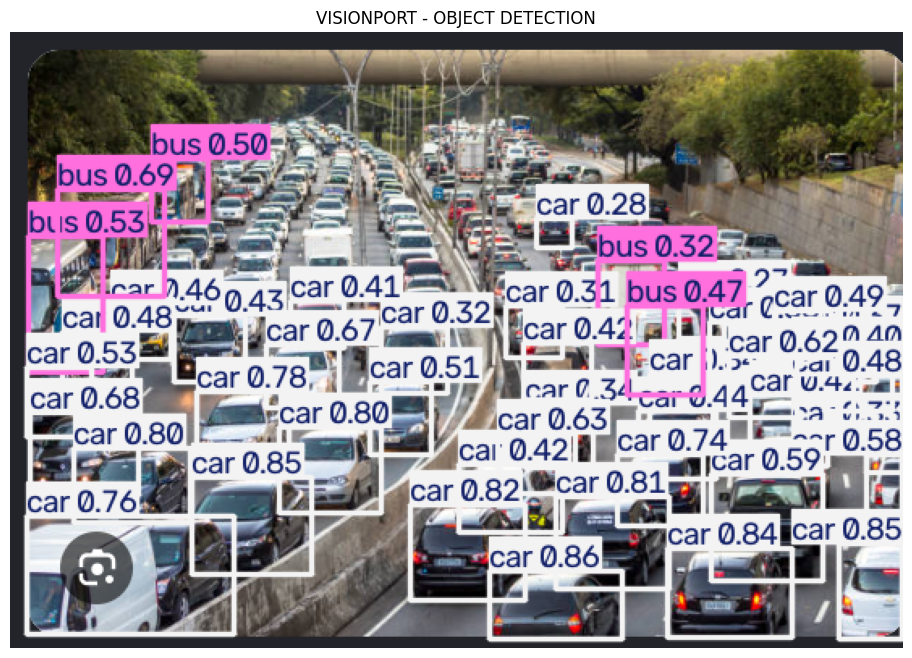


===== DETECTED OBJECTS =====
Object: car | Confidence: 85.87%
Object: car | Confidence: 85.32%
Object: car | Confidence: 84.54%
Object: car | Confidence: 83.90%
Object: car | Confidence: 82.28%
Object: car | Confidence: 81.48%
Object: car | Confidence: 80.26%
Object: car | Confidence: 79.66%
Object: car | Confidence: 78.46%
Object: car | Confidence: 76.38%
Object: car | Confidence: 74.02%
Object: bus | Confidence: 69.22%
Object: car | Confidence: 67.53%
Object: car | Confidence: 66.72%
Object: car | Confidence: 63.02%
Object: car | Confidence: 62.03%
Object: car | Confidence: 59.08%
Object: car | Confidence: 57.91%
Object: car | Confidence: 53.39%
Object: bus | Confidence: 52.53%
Object: car | Confidence: 51.16%
Object: bus | Confidence: 49.92%
Object: car | Confidence: 48.90%
Object: car | Confidence: 48.28%
Object: car | Confidence: 48.10%
Object: bus | Confidence: 46.78%
Object: car | Confidence: 45.71%
Object: car | Confidence: 43.65%
Object: car | Confidence: 42.95%
Object: car |

In [ ]:
# Perform object detection
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# Get detection result
result = results[0]

# Display detected image
detected_image = result.plot()

detected_image = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(detected_image)
plt.axis("off")
plt.title("VISIONPORT - OBJECT DETECTION")
plt.show()

# Print detected objects
print("\n===== DETECTED OBJECTS =====")

if len(result.boxes) > 0:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        print(
            f"Object: {object_name} | "
            f"Confidence: {confidence:.2%}"
        )
else:
    print("No objects detected.")